*Previous notebook: from a single neuron to a network, and the main activation functions (sigmoid, tanh, ReLU, Leaky ReLU, ELU, GELU, Swish, Softmax). — This notebook: the main steps for building a neural network and a 2-layer XOR network implemented from scratch.*

# The main steps for building a Neural Network

- Create (or obtain, if already exists) and preprocess the dataset
- Define the model structure (such as number of input features and outputs)
- Initialize the model's parameters.
- Loop:
   - Calculate current loss (forward propagation)
   - Calculate current gradient (backward propagation)
   - Update parameters (gradient descent)

Tuning the learning rate (which is an example of a "hyperparameter") can make a big difference to the algorithm.

# Implement XOR network

To perform the XOR gate operation, we build a simple two-layer neural network as shown
in the following figure. As you can observe, we have an input layer with two nodes, a
hidden layer with five nodes and an output layers which consist of 1 node:

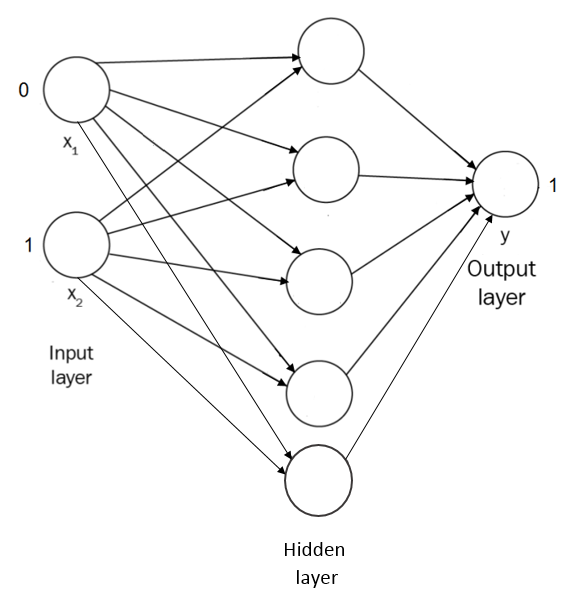

---

### Input: 2 neurons

$x = [x_1, x_2]^T \in \mathbb{R}^{2 \times 1}$

---

### Hidden layer: 5 neurons

Notation -> superscript = layer, subscript = neuron index / connection.

For $j = 1, \dots, 5$:

$$
z^{(1)}_j = w^{(1)}_{j1} x_1 + w^{(1)}_{j2} x_2 + b^{(1)}_j
$$

$$
a^{(1)}_j = \sigma\left(z^{(1)}_j\right)
$$

Expands it in:

$$
z^{(1)}_1 = w^{(1)}_{11} x_1 + w^{(1)}_{12} x_2 + b^{(1)}_1, \quad a^{(1)}_1 = \sigma(z^{(1)}_1)
$$

$$
z^{(1)}_2 = w^{(1)}_{21} x_1 + w^{(1)}_{22} x_2 + b^{(1)}_2, \quad a^{(1)}_2 = \sigma(z^{(1)}_2)
$$

$$
z^{(1)}_3 = w^{(1)}_{31} x_1 + w^{(1)}_{32} x_2 + b^{(1)}_3, \quad a^{(1)}_3 = \sigma(z^{(1)}_3)
$$

$$
z^{(1)}_4 = w^{(1)}_{41} x_1 + w^{(1)}_{42} x_2 + b^{(1)}_4, \quad a^{(1)}_4 = \sigma(z^{(1)}_4)
$$

$$
z^{(1)}_5 = w^{(1)}_{51} x_1 + w^{(1)}_{52} x_2 + b^{(1)}_5, \quad a^{(1)}_5 = \sigma(z^{(1)}_5)
$$

---

### Output layer: 1 neurons

$$
z^{(2)} = w^{(2)}_{1} a^{(1)}_1 + w^{(2)}_{2} a^{(1)}_2 + w^{(2)}_{3} a^{(1)}_3 + w^{(2)}_{4} a^{(1)}_4 + w^{(2)}_{5} a^{(1)}_5 + b^{(2)}
$$

$$
y = \sigma\left(z^{(2)}\right)
$$


### Matrix form

#### First layer

$$
W^{(1)} \in \mathbb{R}^{5 \times 2} =
\begin{bmatrix}
w^{(1)}_{11} & w^{(1)}_{12} \\
w^{(1)}_{21} & w^{(1)}_{22} \\
w^{(1)}_{31} & w^{(1)}_{32} \\
w^{(1)}_{41} & w^{(1)}_{42} \\
w^{(1)}_{51} & w^{(1)}_{52}
\end{bmatrix}
$$

$$
b^{(1)} \in \mathbb{R}^{5 \times 1} =
\begin{bmatrix}
b^{(1)}_1 \\
b^{(1)}_2 \\
b^{(1)}_3 \\
b^{(1)}_4 \\
b^{(1)}_5
\end{bmatrix}
$$

$$
z^{(1)} = W^{(1)} x + b^{(1)}
$$

$$
a^{(1)} = \sigma\left(z^{(1)}\right)
$$

---

### Second layer

$$
W^{(2)} \in \mathbb{R}^{1 \times 5} =
\begin{bmatrix}
w^{(2)}_{1} & w^{(2)}_{2} & w^{(2)}_{3} & w^{(2)}_{4} & w^{(2)}_{5}
\end{bmatrix}
$$

$$
b^{(2)} \in \mathbb{R}
$$

$$
z^{(2)} = W^{(2)} a^{(1)} + b^{(2)}
$$

$$
y = \sigma\left(z^{(2)}\right)
$$

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([ [0, 1], [1, 0], [1, 1],[0, 0] ])
y = np.array([ [1], [1], [0], [0]])

In [2]:
assert x.shape == (4, 2), f"x shape mismatch: {x.shape}"
assert y.shape == (4, 1), f"y shape mismatch: {y.shape}"

Define the number of nodes in each layers

In [3]:
num_input = 2
num_hidden = 5
num_output = 1

Initialize weights and bias randomly. `Wxh` connects the **input layer** to the **hidden layer** — names follow the convention $W_{\text{source} \to \text{dest}}$:

- Shape: $(2 \times 5)$ — 2 input nodes, 5 hidden nodes
- Each value encodes how much influence each input has on each hidden node

In [4]:
Wxh = np.random.randn(num_input, num_hidden)
bh  = np.zeros((1, num_hidden))

In [5]:
assert Wxh.shape == (num_input, num_hidden), f"Wxh shape mismatch: {Wxh.shape}"
assert bh.shape == (1, num_hidden), f"bh shape mismatch: {bh.shape}"

Initialize hidden-to-output weights. `Why` connects the **hidden layer** to the **output layer**:

- Shape: $(5 \times 1)$ — 5 hidden nodes, 1 output node
- Each value encodes how much influence each hidden node has on the output

In [6]:
Why = np.random.randn(num_hidden, num_output)
by  = np.zeros((1, num_output))

In [7]:
assert Why.shape == (num_hidden, num_output), f"Why shape mismatch: {Why.shape}"
assert by.shape == (1, num_output), f"by shape mismatch: {by.shape}"

Define the sigmoid activation function (introduced in the previous notebook):

In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

Define the forward propagation

$$
a^{(1)} = \sigma\left(W^{(1)} x + b^{(1)}\right)
$$

$$
y = \sigma\left(W^{(2)} a^{(1)} + b^{(2)}\right)
$$

In [9]:
def forward_prop(x,Wxh,Why):
    z1 = np.dot(x,Wxh) + bh
    a1 = sigmoid(z1)
    z2 = np.dot(a1,Why) + by
    y_hat = sigmoid(z2)
    
    return z1,a1,z2,y_hat

Define the sigmoid derivative

In [10]:
def sigmoid_derivative(z):
    return np.exp(-z) / ((1 + np.exp(-z)) ** 2)

Define the backward propagation. The forward pass is:

$$x \xrightarrow{W_{xh}} z_1 = x \cdot W_{xh} + b_h \xrightarrow{\sigma} a_1 \xrightarrow{W_{hy}} z_2 = a_1 \cdot W_{hy} + b_y \xrightarrow{\sigma} \hat{y}$$

with cost $J = \frac{1}{2}(y - \hat{y})^2$.

**Output layer gradient** — applying the chain rule to $\frac{\partial J}{\partial W_{hy}}$:

$$\delta_2 = -(y - \hat{y}) \cdot \sigma'(z_2) \qquad \frac{\partial J}{\partial W_{hy}} = a_1^T \cdot \delta_2$$

**Hidden layer gradient** — the error propagates back through $W_{hy}$:

$$\delta_1 = (\delta_2 \cdot W_{hy}^T) \cdot \sigma'(z_1) \qquad \frac{\partial J}{\partial W_{xh}} = x^T \cdot \delta_1$$

In [11]:
def backword_prop(y_hat, z1, a1, z2):
    delta2   = np.multiply(-(y - y_hat), sigmoid_derivative(z2))
    dJ_dWhy  = np.dot(a1.T, delta2)
    delta1   = np.dot(delta2, Why.T) * sigmoid_derivative(z1)
    dJ_dWxh  = np.dot(x.T, delta1)
    return dJ_dWxh, dJ_dWhy

## NumPy Best Practices for Neural Networks

From https://github.com/amanchadha/coursera-deep-learning-specialization/

When implementing neural networks with NumPy, always follow these four guidelines:

1. **Avoid rank-1 arrays** — never use shapes like `(m,)`; they behave unexpectedly with dot products and transposes.
2. **Use explicit 2D shapes** — prefer `(m, 1)` column vectors over flat arrays; use `reshape(m, 1)` when needed.
3. **Assert shapes** — add `assert` statements after every variable definition to catch shape bugs early.
4. **Avoid rank-1 matrices** — always initialize weights and biases with explicit 2D shapes, e.g. `np.random.randn(n, 1)` instead of `np.random.randn(n)`.

Define the cost function — the same squared error used for the AND perceptron:

$$J = \frac{1}{2} \sum (y - \hat{y})^2$$

and set learning rate and number of training iterations:

In [12]:
def cost_function(y, y_hat):
    return 0.5 * np.sum((y - y_hat) ** 2)

alpha          = 1.0
num_iterations = 10_000

Start training of the network

In [13]:
def train_nn(x, y, Wxh, Why, num_iterations, alpha):
    cost_history = []
    for i in range(num_iterations):
        
        #perform forward propagation and predict output
        z1,a1,z2,y_hat = forward_prop(x,Wxh,Why)
        
        #perform backward propagation and calculate gradients
        dJ_dWxh, dJ_dWhy = backword_prop(y_hat, z1, a1, z2)
            
        #update the weights
        Wxh = Wxh -alpha * dJ_dWxh
        Why = Why -alpha * dJ_dWhy
        
        #compute cost
        c = cost_function(y, y_hat)
        
        #store the cost
        cost_history.append(c)

        if i % 1000 == 0:
            print(f"Cost after iteration {i}: {c}")

    return cost_history, y_hat

cost_history, y_hat = train_nn(x, y, Wxh, Why, num_iterations, alpha)

Cost after iteration 0: 0.6259748410432016
Cost after iteration 1000: 0.1214362279611878
Cost after iteration 2000: 0.04044177401619764


Cost after iteration 3000: 0.02215532923398814
Cost after iteration 4000: 0.014836573262485456
Cost after iteration 5000: 0.011015296227537306
Cost after iteration 6000: 0.008701101892256249


Cost after iteration 7000: 0.007161437654735415
Cost after iteration 8000: 0.006068554332345912
Cost after iteration 9000: 0.005255284041163866


Now see the final predictions, so the vector of the weights that we are learned from the training.

In [14]:
print("Final predictions:")
print(y_hat)

Final predictions:
[[0.9549846 ]
 [0.95661577]
 [0.046341  ]
 [0.05657675]]


Plot cost function

Text(0, 0.5, 'Cost')

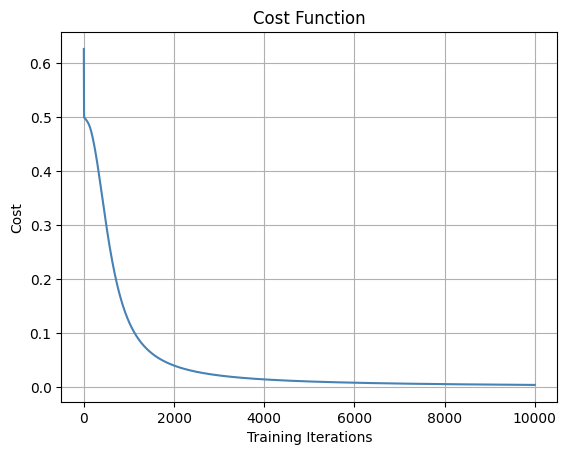

In [15]:
plt.grid()
plt.plot(range(num_iterations),cost_history, color='steelblue')

plt.title('Cost Function')
plt.xlabel('Training Iterations')
plt.ylabel('Cost')